In [1]:
!git clone --quiet --depth 1 --branch rev1 https://github.com/huboqiang/omnialigner.git omnialigner-rev1
!wget -q -c -O rev1-fig3-fair-landmarks.tar.gz https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-fig3-fair-landmarks.tar.gz
!pip install -q numpy==1.26.0 scipy==1.15.3 pandas==2.1.1 matplotlib==3.9.1

Reason for being yanked: <none given>


# OmniAligner — Fig. 3 FAIR landmark benchmark

Recalculate TRE and aTRE directly from all ten released landmark arrays (Prostate and Liver; RAW, CODA, VALIS, DeeperHistReg and OmniAligner). Every metric function is visible below. This is a **scoring reproduction from registered landmarks**, not a rerun of image registration.

Two outputs are deliberately separate: the directly recomputed scores and a historical figure replay. The old display inserted fixed CODA Prostate values and dropped the last Liver aTRE observation. Neither operation is hidden in the recomputed table.

The historical multiplier **0.46** is retained only to reproduce the numerical pipeline. Output coordinates have not been physically calibrated: these results must not be labelled as micrometre accuracy. Prostate aTRE is cumulative mean displacement; Liver aTRE is a linear-fit residual. Their values are not the same endpoint.

Run in a fresh Python 3.10/3.11 notebook directory, in order. CPU is sufficient; no private directories, model weights or GPU are needed.

In [2]:
from pathlib import Path
import hashlib, json, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress
from IPython.display import display

ARCHIVE = Path("rev1-fig3-fair-landmarks.tar.gz").resolve()
CHECKOUT = Path("omnialigner-rev1").resolve()
assert (CHECKOUT / ".git").is_dir(), "Clone did not complete"
assert hashlib.sha256(ARCHIVE.read_bytes()).hexdigest() == "38020db057f3914c78aa1bf631409bedfca3a061213304d37c8cd846c11936d4", "Data checksum mismatch"
DESTINATION = CHECKOUT / "benchmarks/rev1"
with tarfile.open(ARCHIVE, "r:gz") as bundle:
    for member in bundle.getmembers():
        target = (DESTINATION / member.name).resolve()
        assert target.is_relative_to(DESTINATION.resolve())
        assert member.isfile() or member.isdir(), "Unexpected archive member"
    bundle.extractall(DESTINATION)
DATA = DESTINATION / "OmniAligner/data/fig3_fair"
OUTPUT = Path("fig3_fair_outputs").resolve()
OUTPUT.mkdir(exist_ok=True)
manifest = json.loads((DATA / "manifest.json").read_text())
SCALE = manifest["historical_scale"]
METHODS = ["RAW", "CODA", "VALIS", "DHR", "OmniAligner"]
TISSUES = ["Prostate", "Liver"]
plt.rcParams.update({"font.size": 10, "pdf.fonttype": 42, "svg.fonttype": "none"})
print("Verified 10 input sets; outputs:", OUTPUT.name)

Verified 10 input sets; outputs: fig3_fair_outputs


## 1. Load all original coordinates
NPZ files retain every saved landmark (eight per set), original record order and array dtype. The scoring selection of the **first four** landmarks is explicit. A manifest records hashes of the source PTH files and their lossless NPZ exports; no pickle is loaded by this notebook.

In [3]:
inputs = {}
for item in manifest["inputs"]:
    path = DATA / item["file"]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item["npz_sha256"]
    with np.load(path, allow_pickle=False) as arrays:
        records = [[arrays[f"record_{i:03d}_part_{j}"].copy()
                    for j in range(parts)]
                   for i, parts in enumerate(item["parts_per_record"])]
    assert [[len(part) for part in record] for record in records] == item["point_counts"]
    inputs[item["tissue"], item["method"]] = records
inventory = pd.DataFrame([{k: item[k] for k in
                          ["tissue", "method", "records", "atre_definition"]}
                         for item in manifest["inputs"]])
display(inventory)

,tissue,method,records,atre_definition
0,Prostate,RAW,259,cumulative mean displacement
1,Prostate,CODA,259,cumulative mean displacement
2,Prostate,VALIS,260,cumulative mean displacement
3,Prostate,DHR,259,cumulative mean displacement
4,Prostate,OmniAligner,259,cumulative mean displacement
5,Liver,RAW,47,linear-fit residual
6,Liver,CODA,47,linear-fit residual
7,Liver,VALIS,47,linear-fit residual
8,Liver,DHR,47,linear-fit residual
9,Liver,OmniAligner,47,linear-fit residual


## 2. Prepare correspondences
For Prostate VALIS only, form adjacent pairs from the second point set of record *i* and the first set of record *i+1*, exactly as in the source notebook. Prostate has 259 adjacent pairs; Liver has 47 globally corresponding layers (46 adjacent pairs).

In [4]:
def prepare_landmarks(records, method, first_n=4):
    if method == "VALIS" and len(records[0]) > 1:
        records = [[records[i][1], records[i + 1][0]]
                   for i in range(len(records) - 1)]
    # Preserve the source coordinate conversion from [x,y] to [y,x].
    if len(records[0]) == 1:
        return [np.asarray(record[0])[:first_n, ::-1]
                for record in records if len(record[0])], "global"
    pairs = []
    for reference, moving in records:
        assert len(reference) == len(moving)
        if len(reference):
            pairs.append(np.column_stack([np.asarray(reference)[:first_n, ::-1],
                                          np.asarray(moving)[:first_n, ::-1]]))
    return pairs, "pairwise"

prepared = {key: prepare_landmarks(records, key[1])
            for key, records in inputs.items()}

## 3. Compute the metrics directly
**TRE:** Euclidean distance between corresponding points in adjacent layers.

**Prostate aTRE:** for each adjacent pair, average the four displacement vectors; accumulate these vectors along the stack, then take their Euclidean norm. This is not a pointwise path length.

**Liver aTRE:** fit each landmark's x and y trajectories linearly against layer depth, then measure the in-plane residual at every layer. The historical spacing ratio is 5/0.46. No molecular expression or class labels enter these metrics.

In [5]:
def pairwise_tre(points, kind):
    # Scalar operations preserve the source input precision before accumulation.
    n_pairs = len(points) - 1 if kind == "global" else len(points)
    result = np.zeros((n_pairs, len(points[0])))
    for i in range(n_pairs):
        for j in range(len(points[0])):
            if kind == "global":
                y1, x1 = points[i][j]
                y2, x2 = points[i + 1][j]
            else:
                y1, x1, y2, x2 = points[i][j]
            result[i, j] = np.sqrt((y2 - y1)**2 + (x2 - x1)**2)
    return result


def cumulative_atre(points):
    result = np.zeros(len(points))
    cumulative_displacement = np.array([0.0, 0.0])
    for i, pair in enumerate(points):
        mean_displacement = np.array([
            np.nanmean(pair[:, 2] - pair[:, 0]),
            np.nanmean(pair[:, 3] - pair[:, 1])], dtype=float)
        cumulative_displacement += mean_displacement
        result[i] = np.sqrt(cumulative_displacement[0]**2 + cumulative_displacement[1]**2)
    return result


def linear_fit_atre(points, z_spacing):
    stack = np.asarray(points, dtype=float)
    residual = np.full(stack.shape[:2], np.nan)
    z = np.arange(len(stack)) * z_spacing
    for landmark in range(stack.shape[1]):
        y, x = stack[:, landmark, 0], stack[:, landmark, 1]
        valid = ~np.isnan(y)  # Preserve the source's missing-point rule.
        if valid.sum() < 2:
            continue
        slope_x = linregress(z[valid], x[valid]).slope
        slope_y = linregress(z[valid], y[valid]).slope
        fitted_x = x[valid].mean() + (z - z[valid].mean()) * slope_x
        fitted_y = y[valid].mean() + (z - z[valid].mean()) * slope_y
        residual[valid, landmark] = np.hypot(
            y[valid] - fitted_y[valid], x[valid] - fitted_x[valid])
    return residual

scores = {}
for (tissue, method), (points, kind) in prepared.items():
    tre = pairwise_tre(points, kind)
    atre = (cumulative_atre(points) if kind == "pairwise" else
            linear_fit_atre(points, manifest["historical_slice_spacing"] / SCALE))
    scores[tissue, method] = {"TRE": tre * SCALE, "aTRE": atre * SCALE}

## 4. Verify every score against the original implementation
Reference arrays were generated independently by the original `benchmark_kpts` function from the original PTH files. They are used **only for checks**, never to fill or replace calculated scores.

In [6]:
reference_path = DATA / "source_reference_arrays.npz"
assert hashlib.sha256(reference_path.read_bytes()).hexdigest() == manifest["reference_sha256"]
checks = []
with np.load(reference_path, allow_pickle=False) as reference:
    for (tissue, method), metrics in scores.items():
        for metric, values in metrics.items():
            expected = reference[f"{tissue}_{method}_{metric}"]
            np.testing.assert_allclose(values, expected, rtol=1e-10, atol=1e-8, equal_nan=True)
            checks.append({"tissue": tissue, "method": method, "metric": metric,
                           "values": values.size,
                           "max_abs_error": float(np.nanmax(np.abs(values - expected)))})
validation = pd.DataFrame(checks)
validation.to_csv(OUTPUT / "source_parity_checks.csv", index=False)
print(f"Passed: {len(validation)}/20 metric arrays; {validation['values'].sum():,} values")
print("Maximum absolute difference:", validation.max_abs_error.max())

Passed: 20/20 metric arrays; 8,335 values
Maximum absolute difference: 2.2737367544323206e-13


## 5. Summarize the directly recomputed scores
Average over the four landmarks within each pair/layer first, then summarize pairs/layers. Standard deviation uses **ddof=1**, matching pandas in the original figure code. Keep all 47 Liver aTRE layers. The numerical unit below is **historically scaled output-coordinate units**, not μm. An additional export divides by 0.46 to report output-coordinate units.

In [7]:
rows, point_rows = [], []
for (tissue, method), metrics in scores.items():
    for metric, values in metrics.items():
        reduced = values.mean(axis=1) if values.ndim == 2 else values
        rows.append({"tissue": tissue, "method": method, "metric": metric,
                     "n": len(reduced), "mean": np.mean(reduced),
                     "std": np.std(reduced, ddof=1), "min": np.min(reduced),
                     "max": np.max(reduced)})
        for i, value in enumerate(reduced):
            point_rows.append({"tissue": tissue, "method": method, "metric": metric,
                               "pair_or_layer_index": i, "value": float(value)})
computed = pd.DataFrame(rows)
computed.to_csv(OUTPUT / "fig3_direct_recomputed_summary.csv", index=False)
pd.DataFrame(point_rows).to_csv(OUTPUT / "fig3_per_pair_or_layer.csv", index=False)
np.savez_compressed(OUTPUT / "fig3_computed_metric_arrays.npz",
                    **{f"{t}_{m}_{metric}": arr for (t, m), ms in scores.items()
                       for metric, arr in ms.items()})
coordinate_units = computed.copy()
coordinate_units[["mean", "std", "min", "max"]] /= SCALE
coordinate_units.to_csv(OUTPUT / "fig3_output_coordinate_units.csv", index=False)
display(computed.round(6))

,tissue,method,metric,n,mean,std,min,max
0,Prostate,RAW,TRE,259,489.244465,420.317745,33.656759,2013.601681
1,Prostate,RAW,aTRE,259,1153.518786,728.903387,10.454616,2528.885208
2,Prostate,CODA,TRE,259,295.517708,976.942811,20.786337,6538.220275
3,Prostate,CODA,aTRE,259,2178.362501,860.008445,34.356082,3822.145989
4,Prostate,VALIS,TRE,259,31.822814,31.279693,2.708722,217.456762
5,Prostate,VALIS,aTRE,259,406.625698,178.005820,5.238905,660.754819
6,Prostate,DHR,TRE,259,13.666264,17.957255,1.963108,95.507978
7,Prostate,DHR,aTRE,259,649.450039,378.296326,4.243425,1214.963012
8,Prostate,OmniAligner,TRE,259,16.543504,10.821631,0.000000,95.013742
9,Prostate,OmniAligner,aTRE,259,661.470794,393.135415,5.519888,1153.270827


## 6. Plot directly recomputed mean errors
The panels compare methods within one tissue and one endpoint. A lower value is better. No confidence intervals, significance claims or physical-unit conversion are implied.

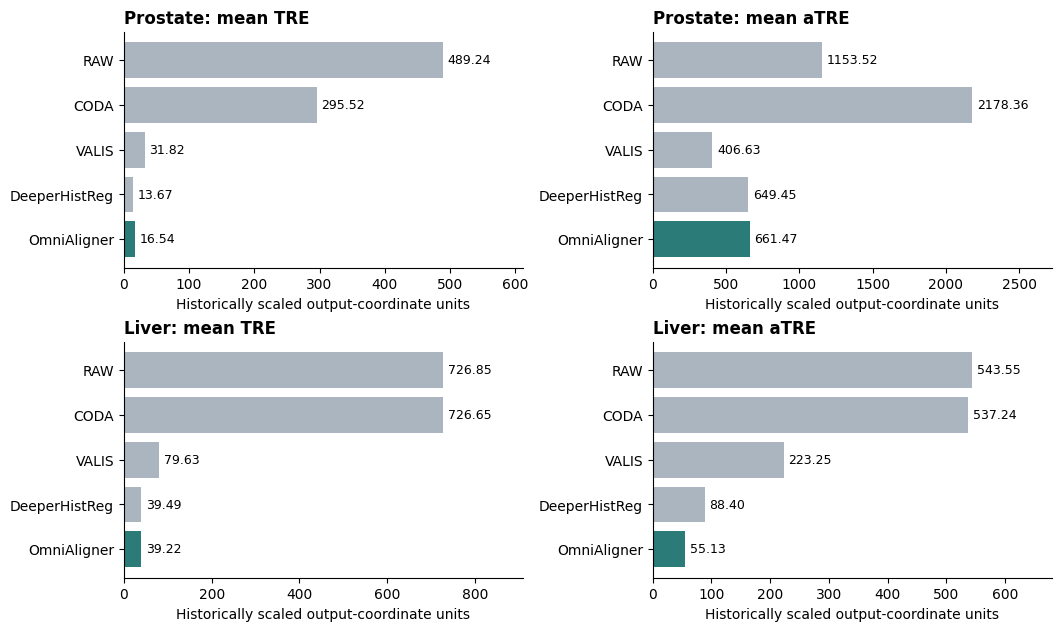

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.2), constrained_layout=True)
for row, tissue in enumerate(TISSUES):
    for col, metric in enumerate(["TRE", "aTRE"]):
        ax = axes[row, col]
        subset = computed.query("tissue == @tissue and metric == @metric").set_index("method").loc[METHODS]
        values = subset["mean"].to_numpy()
        colors = ["#2b7b78" if m == "OmniAligner" else "#aab5bf" for m in METHODS]
        bars = ax.barh(range(len(METHODS)), values, color=colors)
        ax.set_yticks(range(len(METHODS)), ["DeeperHistReg" if m == "DHR" else m for m in METHODS])
        ax.invert_yaxis()
        ax.set_xlim(0, values.max() * 1.25)
        for bar, value in zip(bars, values):
            ax.text(value + values.max()*0.015, bar.get_y()+bar.get_height()/2,
                    f"{value:.2f}", va="center", fontsize=9)
        ax.set_title(f"{tissue}: mean {metric}", loc="left", weight="bold")
        ax.set_xlabel("Historically scaled output-coordinate units")
        ax.spines[["top", "right"]].set_visible(False)
fig.savefig(OUTPUT / "Fig3_FAIR_direct_recomputed.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "Fig3_FAIR_direct_recomputed.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Reconstruct the historical display separately
This section reproduces the numerical processing in source cell 9, including two operations absent from the direct table:

1. Pairing TRE and aTRE rows and dropping missing values excludes the **last Liver aTRE layer**.
2. The Prostate CODA recomputed row is removed and replaced by six fixed values recorded in the source plotting code: TRE mean/std/max 37.1/34.8/291.9 and aTRE mean/std/max 365.4/220.7/771.7. Their minima remain missing. These are **historical fixed reference entries**, not values recalculated from the supplied CODA landmarks; their original external attribution is not established by this notebook.

For each displayed column, `scaled = clip((value − best)/(RAW − best), 0, 1)`. Lower is better. This produces a dimensionless display, not physical accuracy. The untouched original manuscript PDF is not overwritten.

In [9]:
historical_rows = []
for (tissue, method), metrics in scores.items():
    tre = metrics["TRE"].mean(axis=1)
    atre = metrics["aTRE"].mean(axis=1) if metrics["aTRE"].ndim == 2 else metrics["aTRE"]
    if len(tre) < len(atre):
        tre = np.r_[tre, np.nan]
    paired = pd.DataFrame({"TRE": tre, "aTRE": atre}).dropna()
    for metric in ["TRE", "aTRE"]:
        values = paired[metric]
        historical_rows.append({"tissue": tissue, "method": method, "metric": metric,
                               "mean": values.mean(), "std": values.std(),
                               "min": values.min(), "max": values.max()})
historical = pd.DataFrame(historical_rows)
for metric, values in {"TRE": [37.1, 34.8, np.nan, 291.9],
                       "aTRE": [365.4, 220.7, np.nan, 771.7]}.items():
    mask = ((historical.tissue == "Prostate") & (historical.method == "CODA") &
            (historical.metric == metric))
    historical.loc[mask, ["mean", "std", "min", "max"]] = values
historical.to_csv(OUTPUT / "fig3_historical_display_values.csv", index=False)
columns = [(t, m, stat) for t in TISSUES for m in ["TRE", "aTRE"]
           for stat in ["mean", "std", "min", "max"]]
wide = pd.DataFrame(index=METHODS)
for tissue, metric, stat in columns:
    values = historical.query("tissue == @tissue and metric == @metric").set_index("method")[stat]
    wide[f"{tissue}_{metric}_{stat}"] = values
scaled = ((wide - wide.min()) / (wide.loc["RAW"] - wide.min())).clip(0, 1)
scaled.to_csv(OUTPUT / "fig3_historical_scaled_matrix.csv")
assert historical.query("tissue == 'Prostate' and method == 'CODA'")["min"].isna().all()
display(wide.round(4))

,Prostate_TRE_mean,Prostate_TRE_std,Prostate_TRE_min,Prostate_TRE_max,Prostate_aTRE_mean,Prostate_aTRE_std,Prostate_aTRE_min,Prostate_aTRE_max,Liver_TRE_mean,Liver_TRE_std,Liver_TRE_min,Liver_TRE_max,Liver_aTRE_mean,Liver_aTRE_std,Liver_aTRE_min,Liver_aTRE_max
RAW,489.2445,420.3177,33.6568,2013.6017,1153.5188,728.9034,10.4546,2528.8852,726.8485,465.9582,93.0735,1936.2948,545.6308,252.1896,66.0521,1263.6130
CODA,37.1000,34.8000,NaN,291.9000,365.4000,220.7000,NaN,771.7000,726.6478,868.3648,27.4914,2785.8576,546.2405,549.1175,79.1887,2171.8692
VALIS,31.8228,31.2797,2.7087,217.4568,406.6257,178.0058,5.2389,660.7548,79.6298,186.7474,6.3598,1069.6046,224.0709,158.7184,26.2859,607.5813
DHR,13.6663,17.9573,1.9631,95.5080,649.4500,378.2963,4.2434,1214.9630,39.4934,52.2111,6.0932,257.3014,87.8700,40.7396,23.8175,220.9227
OmniAligner,16.5435,10.8216,0.0000,95.0137,661.4708,393.1354,5.5199,1153.2708,39.2168,29.7191,0.0000,134.0335,55.0617,19.5790,31.1266,136.6748


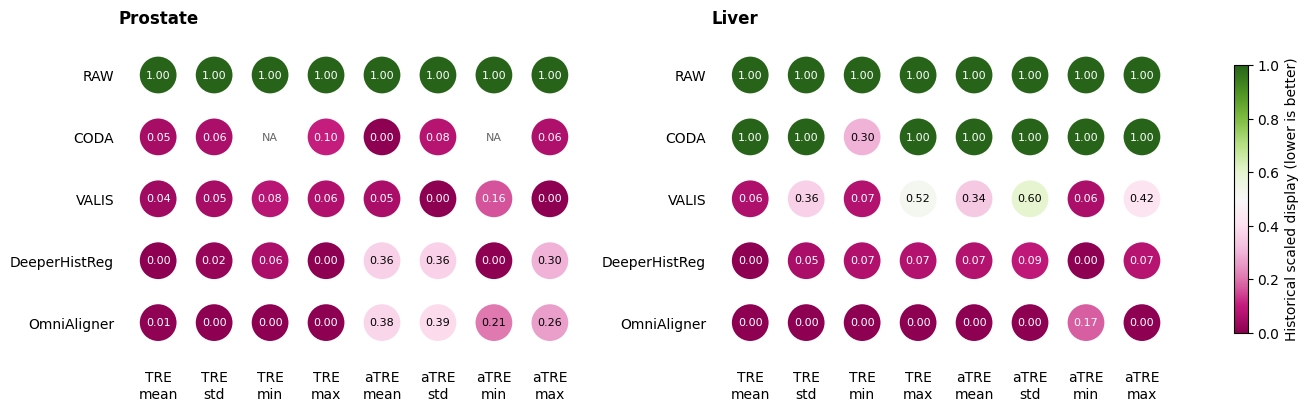

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for ax, tissue in zip(axes, TISSUES):
    matrix = scaled[[c for c in scaled.columns if c.startswith(tissue + "_")]]
    xx, yy = np.meshgrid(np.arange(8), np.arange(5))
    image = ax.scatter(xx.ravel(), yy.ravel(), c=matrix.to_numpy().ravel(),
                       cmap="PiYG", vmin=0, vmax=1, s=700, edgecolors="none")
    for y, row in enumerate(matrix.to_numpy()):
        for x, value in enumerate(row):
            if np.isfinite(value):
                ax.text(x, y, f"{value:.2f}", ha="center", va="center", fontsize=8,
                        color="black" if 0.2 < value < 0.8 else "white")
            else:
                ax.text(x, y, "NA", ha="center", va="center", color="#666666", fontsize=8)
    ax.set_xticks(range(8), [f"{m}\n{s}" for m in ["TRE", "aTRE"]
                            for s in ["mean", "std", "min", "max"]])
    ax.set_yticks(range(5), ["DeeperHistReg" if m == "DHR" else m for m in METHODS])
    ax.set_ylim(4.7, -0.7)
    ax.set_xlim(-0.7, 7.7)
    ax.set_title(tissue, loc="left", weight="bold")
    ax.spines[:].set_visible(False)
    ax.tick_params(length=0)
fig.colorbar(image, ax=axes, shrink=0.8, label="Historical scaled display (lower is better)")
fig.savefig(OUTPUT / "Fig3_FAIR_historical_display.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "Fig3_FAIR_historical_display.png", dpi=180, bbox_inches="tight")
plt.show()

## Interpretation and provenance
The directly recomputed arrays give OmniAligner mean TRE/aTRE **16.54/661.47** in Prostate and **39.22/55.13** in Liver, with the historical 0.46 multiplier. DeeperHistReg has lower Prostate mean TRE and VALIS has lower Prostate mean aTRE. OmniAligner has the lowest directly recomputed mean TRE and aTRE among these five Liver conditions. These are results for the supplied landmark sets, not universal superiority or physically calibrated micrometre errors.

The historical display's Liver aTRE summary differs because it excludes the final layer. The CODA Prostate fixed-reference display also differs substantially from its saved-landmark calculation. The notebook exports both, rather than silently substituting either.

Source: archived `Figure2_HE_3D.ipynb` cells 5–7 and 9 (zero-based), and `omnialigner/metrics/regbenchmark_py/{utils,tre,rtre,__init__}.py`. The manifest stores original file paths for provenance only; no execution step accesses them.

In [11]:
report = {"input_sets": len(inputs), "metric_arrays_checked": len(validation),
          "values_checked": int(validation["values"].sum()),
          "max_abs_error": float(validation.max_abs_error.max()),
          "historical_scale": SCALE, "physical_calibration_verified": False,
          "point_selection": "first four per set, source order",
          "prostate_atre": "cumulative mean displacement",
          "liver_atre": "linear-fit residual",
          "source_notebook_sha256": manifest["source_notebook_sha256"],
          "data_archive_sha256": hashlib.sha256(ARCHIVE.read_bytes()).hexdigest()}
(OUTPUT / "validation.json").write_text(json.dumps(report, indent=2) + "\n")
print(json.dumps(report, indent=2))

{
  "input_sets": 10,
  "metric_arrays_checked": 20,
  "values_checked": 8335,
  "max_abs_error": 2.2737367544323206e-13,
  "historical_scale": 0.46,
  "physical_calibration_verified": false,
  "point_selection": "first four per set, source order",
  "prostate_atre": "cumulative mean displacement",
  "liver_atre": "linear-fit residual",
  "source_notebook_sha256": "bd54d87f0fbfe7e5ad2c4750d628d795d7c6550cb6a2eee51f40a009f7bcae7a",
  "data_archive_sha256": "38020db057f3914c78aa1bf631409bedfca3a061213304d37c8cd846c11936d4"
}
